Paso 1 — Importar librerías

En Colab:

In [ ]:
import numpy as np
from IPython.display import Audio, display
import matplotlib.pyplot as plt

Paso 2 — Crear nuestro "espacio latente"

Aquí se define un espacio 2D.

Un espacio latente es una representación donde cada punto contiene una combinación de características. Al inicio uso un espacio 2D porque es fácil de visualizar:

x → cambia una característica sonora (ej. frecuencia/timbre)
y → cambia otra característica (ej. armónicos/textura)

Entonces:

(0.2, 0.8)  → un tipo de sonido
(0.8, 0.2)  → otro tipo de sonido

No se está diciendo que el sonido "vive" realmente en 2 dimensiones; es un modelo simplificado para aprender la idea. Más adelante, con VAE u otros modelos, el espacio latente será aprendido por la máquina y tendrá muchas dimensiones.

In [ ]:
latent_x = 0.5
latent_y = 0.5

     y

          1
          |
          |
0 --------+-------- 1
          |
          |
          0

          x
          Cada punto será un sonido diferente.

Paso 3 — Convertir posición en sonido

Creamos una función:

In [ ]:
def latent_to_sound(x, y, duration=2, sr=44100):

    t = np.linspace(
        0,
        duration,
        int(sr*duration),
        False
    )

    # eje X controla frecuencia
    freq = 100 + x * 900

    # eje Y controla armónicos
    harmonic = 1 + int(y*10)

    signal = np.sin(
        2*np.pi*freq*t
    )

    signal += 0.3*np.sin(
        2*np.pi*(freq*harmonic)*t
    )

    return signal

Aquí aparece el primer concepto importante:

espacio matemático
        ↓
síntesis sonora

Paso 4 — Escuchar un punto

In [ ]:
sound = latent_to_sound(
    0.2,
    0.8
)

Audio(sound, rate=44100)

Ahora se puede cambiar:

sound = latent_to_sound(
    0.8,
    0.2
)

y se escucha cómo cambia.

Paso 5 — Visualizar el espacio

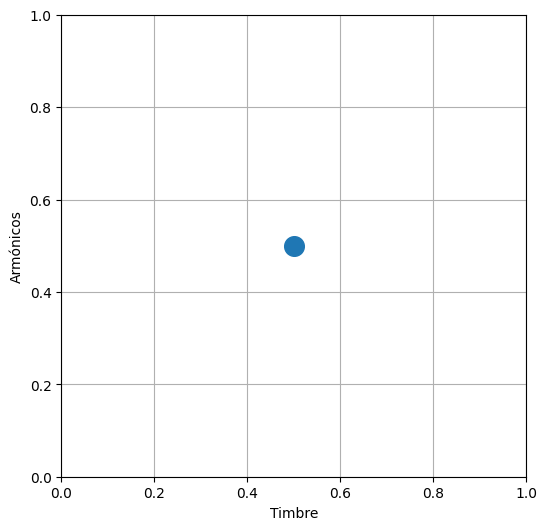

In [ ]:
plt.figure(figsize=(6,6))

plt.scatter(
    latent_x,
    latent_y,
    s=200
)

plt.xlim(0,1)
plt.ylim(0,1)

plt.xlabel("Timbre")
plt.ylabel("Armónicos")

plt.grid()

plt.show()

Paso 6 — Teclado (versión simple)

En Colab es posible usar controles con widgets:

In [ ]:
from ipywidgets import interact

@interact(
    x=(0,1,0.05),
    y=(0,1,0.05)
)

def explorar(x=0.5,y=0.5):

    sonido = latent_to_sound(
        x,y
    )

    display(
        Audio(
            sonido,
            rate=44100
        )
    )

interactive(children=(FloatSlider(value=0.5, description='x', max=1.0, step=0.05), FloatSlider(value=0.5, desc…

Ahora tienes dos controles:

X  → movimiento horizontal
Y  → movimiento vertical

y cada posición produce un sonido.

¿Por qué este primer ejercicio importa ?

Porque se está construyendo la idea central:

TTT2:

gesto
 ↓
zona textil
 ↓
sonido asociado

001:

posición
 ↓
espacio latente
 ↓
sonido continuo

El siguiente paso será:

002 — Crear un espacio latente aprendido con un Autoencoder

Ahí ya no se diseña el mapa. La máquina empieza a encontrar relaciones.

Después:

003 — VAE + generación sonora

004 — SOM organizando el espacio

005 — reemplazar teclado por sensores textiles MPR121